In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [49]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor,GradientBoostingRegressor

In [50]:
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10,6)
pd.set_option('display.max_columns',None)

In [51]:
df = pd.read_csv('medical_insurance.csv')

In [52]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
2767,47,female,45.320,1,no,southeast,8569.86180
2768,21,female,34.600,0,no,southwest,2020.17700
2769,19,male,26.030,1,yes,northwest,16450.89470
2770,23,male,18.715,0,no,northwest,21595.38229


In [53]:
print(f'Baris : {df.shape[0]}')
print(f'Kolom : {df.shape[1]}')
df.info()

Baris : 2772
Kolom : 7
<class 'pandas.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2772 non-null   int64  
 1   sex       2772 non-null   str    
 2   bmi       2772 non-null   float64
 3   children  2772 non-null   int64  
 4   smoker    2772 non-null   str    
 5   region    2772 non-null   str    
 6   charges   2772 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 195.5 KB


In [54]:
df.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [55]:
df.duplicated().sum()

np.int64(1435)

In [83]:
df.drop_duplicates(inplace=True)

In [84]:
df.describe()

,age,bmi,children,charges,log_charges
count,1337.000000,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487,9.100097
std,14.044333,6.100468,1.205571,12110.359656,0.918551
min,18.000000,15.960000,0.000000,1121.873900,7.023647
25%,27.000000,26.290000,0.000000,4746.344000,8.465341
50%,39.000000,30.400000,1.000000,9386.161300,9.147098
75%,51.000000,34.700000,2.000000,16657.717450,9.720689
max,64.000000,53.130000,5.000000,63770.428010,11.063061


In [85]:
df_counts = df.groupby(list(df.columns)).size().reset_index(name='count')

In [59]:
df_counts['count'].value_counts().sort_index()

count
2    1288
4      49
Name: count, dtype: int64

In [86]:
for col in ['sex','smoker','region']:
  print(col.center(20))
  print(df[col].value_counts())
  print(df[col].value_counts(normalize=True).round(3))


        sex         
sex
male      675
female    662
Name: count, dtype: int64
sex
male      0.505
female    0.495
Name: proportion, dtype: float64
       smoker       
smoker
no     1063
yes     274
Name: count, dtype: int64
smoker
no     0.795
yes    0.205
Name: proportion, dtype: float64
       region       
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64
region
southeast    0.272
southwest    0.243
northwest    0.242
northeast    0.242
Name: proportion, dtype: float64


In [87]:
for col in ['age','bmi','children','charges']:
  print(f'{col}: skew={df[col].skew():3f},kurtosis : {df[col].kurtosis():3f}')

age: skew=0.054781,kurtosis : -1.244406
bmi: skew=0.283914,kurtosis : -0.052947
children: skew=0.937421,kurtosis : 0.200954
charges: skew=1.515391,kurtosis : 1.604221


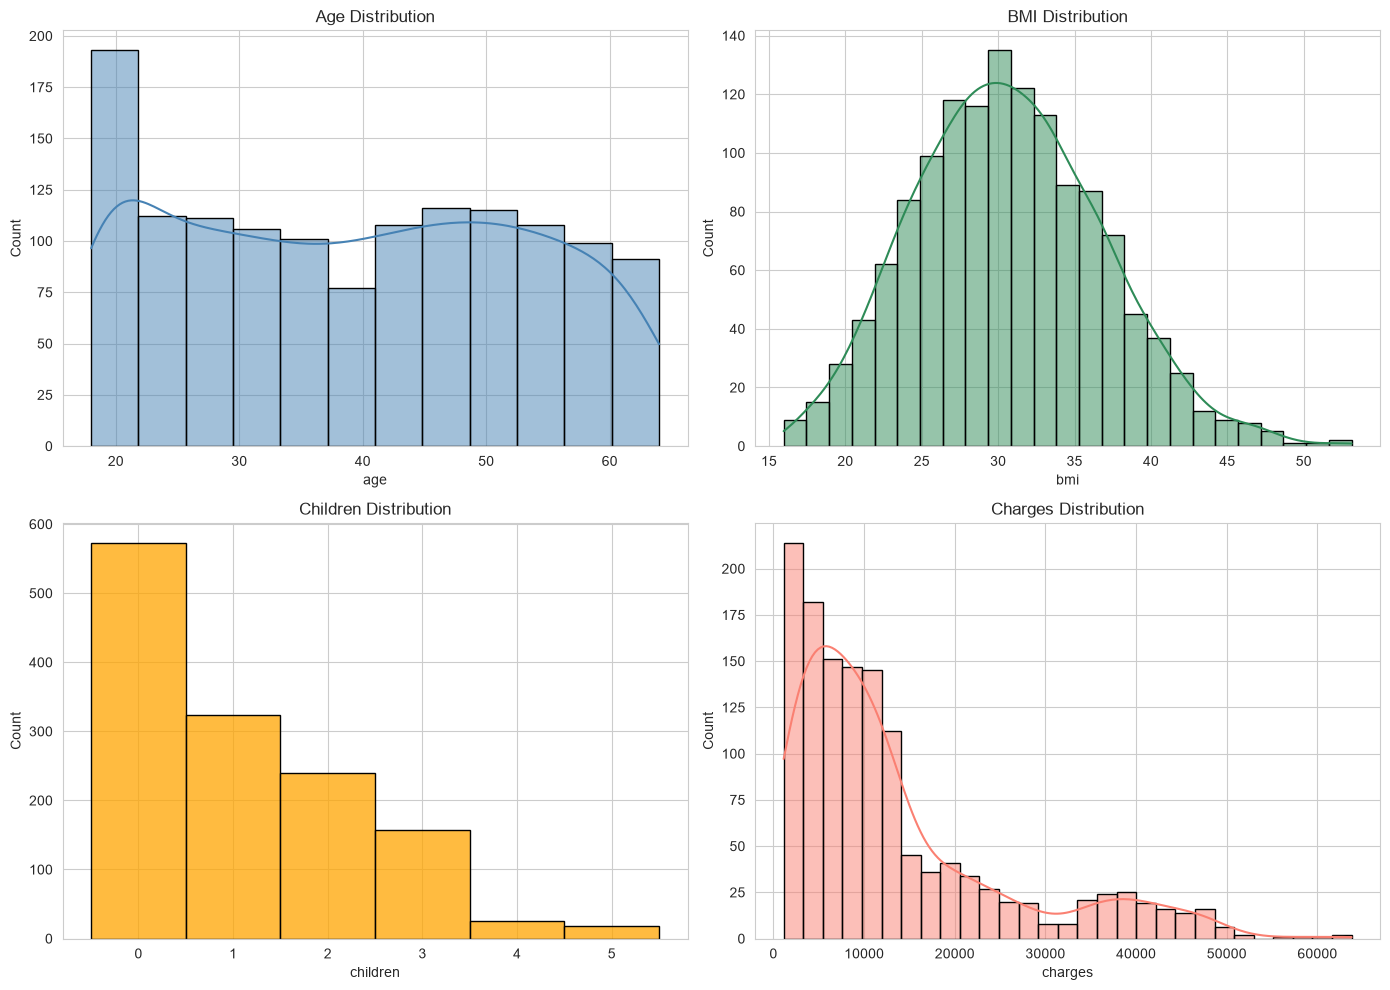

In [88]:
from matplotlib import figure
fig, axes = plt.subplots(2,2, figsize=(14,10))
sns.histplot(df['age'],kde=True,ax=axes[0,0],color='steelblue',edgecolor='black')
axes[0,0].set_title('Age Distribution')
sns.histplot(df['bmi'],kde=True,ax=axes[0,1],color='seagreen',edgecolor='black')
axes[0,1].set_title('BMI Distribution')
sns.histplot(df['children'],discrete=True,ax=axes[1,0],color='orange',edgecolor='black')
axes[1,0].set_title('Children Distribution')
sns.histplot(df['charges'],kde=True,ax=axes[1,1],color='salmon',edgecolor='black')
axes[1,1].set_title('Charges Distribution')
plt.tight_layout()
plt.show()

In [89]:
for col in ['bmi','charges']:
  q1,q3 = df[col].quantile([0.25,0.75])
  iqr = q3-q1
  lower_bound = q1 - 1.5*iqr
  upper_bound = q3 + 1.5*iqr
  out = df[(df[col] < lower_bound) | (df[col] > upper_bound)].shape[0]
  print(f'{col}: bounds = ({lower_bound:.1f},{upper_bound:.1f}), outliers= {out} ({out/len(df) * 100: .1f}%)')

bmi: bounds = (13.7,47.3), outliers= 9 ( 0.7%)
charges: bounds = (-13120.7,34524.8), outliers= 139 ( 10.4%)


In [90]:
df.groupby('smoker')['charges'].agg(['mean','median','std','count'])

,mean,median,std,count
smoker,,,,
no,8440.660307,7345.72660,5992.973800,1063
yes,32050.231832,34456.34845,11541.547176,274


In [91]:
def bmi_category(bmi):
  if bmi < 18.5:
    return 'underweight'
  elif bmi < 25:
    return 'normal'
  elif bmi < 30:
    return 'overweight'
  else:
    return 'obese'

In [93]:
df['bmi_category'] = df['bmi'].apply(bmi_category)

In [94]:
df['bmi_category'].value_counts()

bmi_category
obese          706
overweight     386
normal         225
underweight     20
Name: count, dtype: int64

In [95]:
df.groupby('bmi_category')['charges'].mean().sort_values(ascending=False).round(2)

bmi_category
obese          15572.04
overweight     10987.51
normal         10409.34
underweight     8852.20
Name: charges, dtype: float64

In [96]:
df['log_charges'] = np.log1p(df['charges'])

In [97]:
df['charges'].skew()

np.float64(1.5153909108403483)

In [98]:
df['log_charges'].skew()

np.float64(-0.08955835073325419)

In [99]:
df_model = pd.get_dummies(df,columns=['sex','smoker','region','bmi_category'],drop_first=True)

In [100]:
feature_cols = [c for c in df_model.columns if c not in ['charges','log_charges']]

In [101]:
X = df_model[feature_cols]
y = df_model['log_charges']

In [102]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

In [103]:
print(f'Training : {len(X_train)}')
print(f'Testing  : {len(X_test)}')

Training : 1069
Testing  : 268


In [104]:
y_test_real = np.expm1(y_test)
candidate_models = {
 'Linear Regression' : LinearRegression(),
 'Random Forest' : RandomForestRegressor(n_estimators=300,max_depth=6,n_jobs=-1),
 'Gradient Boosting': GradientBoostingRegressor(n_estimators=300,max_depth=3)
}

trained_model = {}
metrics_row = []
for model_name,model in candidate_models.items():
 model.fit(X_train,y_train)
 y_pred_log = model.predict(X_test)
 y_pred = np.expm1(y_pred_log)
 mae = mean_absolute_error(y_test_real,y_pred)
 mse = mean_squared_error(y_test_real,y_pred)
 r2 = r2_score(y_test_real,y_pred)
 trained_model[model_name] = model
 metrics_row.append({'model' : model_name,'Mae' : mae,'Mse' : mse, 'R2': r2})
 print(f'{model_name} R2 : {r2:.4f} MAE : {mae:.2f} MSE : {mse:.2f}')

Linear Regression R2 : 0.4316 MAE : 4672.55 MSE : 82040356.85
Random Forest R2 : 0.8148 MAE : 2387.63 MSE : 26724536.05
Gradient Boosting R2 : 0.7904 MAE : 2752.40 MSE : 30257317.32


In [105]:
results = pd.DataFrame(metrics_row).sort_values(by='R2',ascending=False).reset_index(drop=True)

In [106]:
results.round(4)

,model,Mae,Mse,R2
0,Random Forest,2387.6339,2.672454e+07,0.8148
1,Gradient Boosting,2752.4003,3.025732e+07,0.7904
2,Linear Regression,4672.5513,8.204036e+07,0.4316


In [107]:
best_model_name = results.loc[0,'model']
best_model = trained_model[best_model_name]

In [108]:
best_model_name

'Random Forest'

In [109]:
best_model

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal 

In [111]:
import joblib 
joblib.dump(best_model, 'insurance_model.pkl')
joblib.dump(feature_cols, 'model_features.pkl')

['model_features.pkl']

In [112]:
joblib.dump(best_model_name, 'model_nama.pkl')

['model_nama.pkl']